In [13]:
"""展示laptop_test数据集(ground truth)的格式"""
from datasets import load_from_disk

dataset = load_from_disk("./data/laptop_test").to_pandas()  # type: ignore
print(dataset.shape)
dataset.head()

(638, 5)


,sentence,object,sentiment,is implicit,id
0,"boot time is super fast, around anywhere from ...",Boot time,positive,False,0
1,tech support would not fix the problem unless ...,tech support,negative,False,1
2,set up was easy.,Set up,positive,False,2
3,did not enjoy the new windows 8 and touchscree...,Windows 8,negative,False,3
4,did not enjoy the new windows 8 and touchscree...,touchscreen functions,negative,False,4


In [14]:
"""展示laptop_test (model output)数据集的格式"""
import pandas as pd

data = pd.read_parquet("./eval/laptop_test.parquet")
print(data.shape)
data.head()

(81664, 3)


,index,output,output_tokens
0,0,"The sentence describes boot time as ""super fas...",49
1,0,"The sentence describes boot time as ""super fas...",46
2,0,"The sentence describes boot time as ""super fas...",49
3,0,"The sentence states that ""boot time is super f...",46
4,0,"The sentence describes boot time as ""super fas...",45


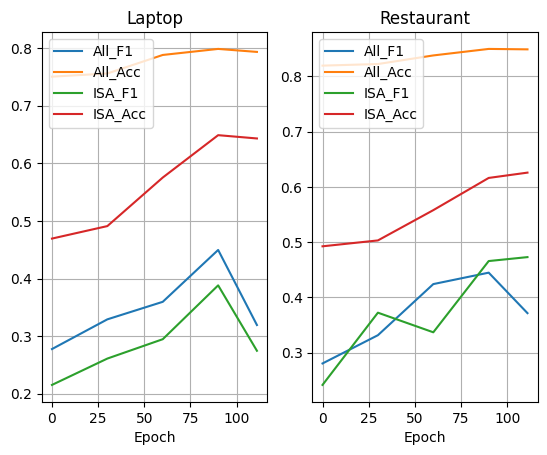

In [15]:
"""绘制图表"""
import matplotlib.pyplot as plt
import pandas as pd

result_laptop = pd.read_csv("./results/grpo_2/results_rl_on_laptop.csv")
result_restaurant = pd.read_csv("./results/grpo_2/results_rl_on_restaurant.csv")

data_dict = {
    "Laptop": result_laptop,
    "Restaurant": result_restaurant,
}

dataset_name_list = ["Laptop", "Restaurant"]
cols = ["All_F1", "All_Acc", "ISA_F1", "ISA_Acc"]
_, ax = plt.subplots(nrows=1, ncols=2)
for i, dataset_name in enumerate(dataset_name_list):
    for col in cols:
        ax[i].plot([0, 30, 60, 90, 111], data_dict[dataset_name][col], label=col)
    ax[i].set_title(dataset_name)
    ax[i].set_xlabel("Epoch")
    ax[i].grid(True)
    ax[i].legend()

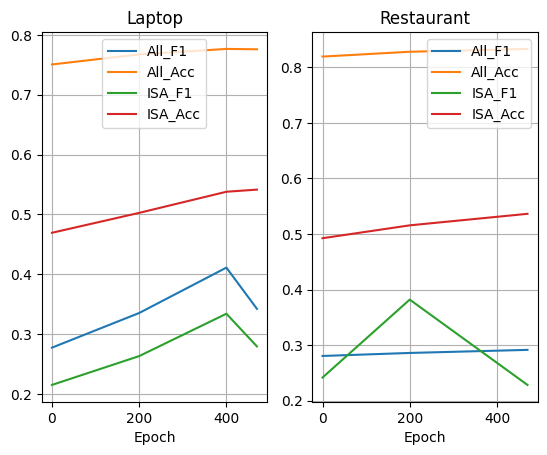

In [16]:
"""绘制图表"""
import matplotlib.pyplot as plt
import pandas as pd

result_laptop = pd.read_csv("./results/grpo_1/laptop.csv")
result_restaurant = pd.read_csv("./results/grpo_1/restaurant.csv")

cols = ["All_F1", "All_Acc", "ISA_F1", "ISA_Acc"]
_, ax = plt.subplots(nrows=1, ncols=2)
for col in cols:
    ax[0].plot([0, 200, 400, 470], result_laptop[col], label=col)
ax[0].set_title("Laptop")
ax[0].set_xlabel("Epoch")
ax[0].grid(True)
ax[0].legend()

for col in cols:
    ax[1].plot([0, 200, 470], result_restaurant[col], label=col)
ax[1].set_title("Restaurant")
ax[1].set_xlabel("Epoch")
ax[1].grid(True)
ax[1].legend()

In [17]:
"""简单输出结果"""
import pandas as pd

result_laptop = pd.read_csv("./results/grpo_2/results_rl_on_laptop.csv")
# 设置精度为3位
pd.set_option("display.precision", 3)
result_laptop[["数据集", "ISA_F1", "ISA_Acc", "All_F1", "All_Acc"]]

,数据集,ISA_F1,ISA_Acc,All_F1,All_Acc
0,laptop_test_base,0.215,0.469,0.278,0.751
1,laptop_test_30,0.261,0.491,0.329,0.756
2,laptop_test_60,0.295,0.575,0.360,0.788
3,laptop_test_90,0.388,0.649,0.450,0.799
4,laptop_test_111,0.275,0.643,0.319,0.793


In [18]:
result_restaurant = pd.read_csv("./results/grpo_2/results_rl_on_restaurant.csv")
result_restaurant[["数据集", "ISA_F1", "ISA_Acc", "All_F1", "All_Acc"]]

,数据集,ISA_F1,ISA_Acc,All_F1,All_Acc
0,restaurant_test_base,0.242,0.492,0.280,0.819
1,restaurant_test_30,0.372,0.503,0.332,0.822
2,restaurant_test_60,0.337,0.558,0.424,0.838
3,restaurant_test_90,0.466,0.616,0.445,0.849
4,restaurant_test_111,0.473,0.626,0.371,0.849


In [19]:
"""简单输出结果"""
import pandas as pd

result_laptop = pd.read_csv("./results/grpo_1/laptop.csv")
result_restaurant = pd.read_csv("./results/grpo_1/restaurant.csv")
# 设置精度为3位
pd.set_option("display.precision", 3)
print(result_laptop[["数据集", "ISA_F1", "ISA_Acc", "All_F1", "All_Acc"]])
print(result_restaurant[["数据集", "ISA_F1", "ISA_Acc", "All_F1", "All_Acc"]])

                数据集  ISA_F1  ISA_Acc  All_F1  All_Acc
0  laptop_test_base   0.215    0.469   0.278    0.751
1   laptop_test_200   0.263    0.503   0.335    0.767
2   laptop_test_400   0.334    0.538   0.411    0.776
3   laptop_test_470   0.280    0.541   0.342    0.776
                    数据集  ISA_F1  ISA_Acc  All_F1  All_Acc
0  restaurant_test_base   0.242    0.492   0.280    0.819
1   restaurant_test_200   0.382    0.516   0.286    0.828
2   restaurant_test_470   0.228    0.536   0.291    0.833
